# 02 描述統計：台灣人過得怎麼樣？

先看幾個基本事實：幸福分數的分布、隨年齡與人生狀態的差異、工作/家庭/經濟三個領域的滿意度，以及 18 年來的變化。
這些事實是故事的「場景」：讀者要先知道大家現在大概在哪裡，後面才看得懂「什麼讓人更幸福」。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from psfd_utils import *
plt = setup_plot()
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
long = pd.read_csv(DERIVED / "long_2007_2024.csv", low_memory=False)
main["age_g"] = pd.cut(main.age, [0, 34, 44, 54, 64, 120], labels=["≤34", "35–44", "45–54", "55–64", "65+"])
main["inc_q"] = main.groupby("year").income.transform(lambda s: pd.qcut(s.where(s > 0), 5, labels=False, duplicates="drop") + 1)

## 1. 幸福分數（0–100）的整體分布與各群體平均（2020–2024 合併）

In [2]:
def grp(col, d=main):
    t = d.groupby(col, observed=True).swb.agg(["mean", "std", "count"])
    t["se"] = t["std"] / np.sqrt(t["count"])
    return t.round(2)

print("全體：平均", round(main.swb.mean(), 1), "標準差", round(main.swb.std(), 1))
for col in ["year", "age_g", "female", "marital", "employed", "has_kids", "kid_under6", "inc_q"]:
    print(f"\n== {col}"); print(grp(col).to_string())

全體：平均 66.0 標準差 17.5

== year
       mean    std  count    se
year                           
2020  65.75  17.64   5630  0.24
2022  65.12  17.53   5554  0.24
2024  67.09  17.38   5318  0.24

== age_g
        mean    std  count    se
age_g                           
≤34    64.90  16.80   3679  0.28
35–44  65.14  17.12   7728  0.19
45–54  66.37  16.67   1812  0.39
55–64  67.23  18.33    981  0.59
65+    69.62  19.75   2302  0.41

== female
         mean    std  count    se
female                           
0.0     65.76  17.09   8635  0.18
1.0     66.20  18.01   7867  0.20

== marital
            mean    std  count    se
marital                             
divorced   62.40  18.53    888  0.62
married    68.06  16.96   9272  0.18
never      63.08  17.06   5461  0.23
separated  58.19  20.61     64  2.58
widowed    66.31  21.77    777  0.78

== employed
           mean    std  count    se
employed                           
0.0       66.56  20.01   3271  0.35
1.0       65.84  16.86  13214  

## 2. 三個領域的滿意度分布

In [3]:
lab = {1: "很不滿意", 2: "不太滿意", 3: "還算滿意", 4: "很滿意"}
dist = pd.DataFrame({k: main[v].map(lab).value_counts(normalize=True) for k, v in
                     [("工作（有工作者）", "jobsat"), ("家庭生活", "famsat"), ("個人經濟", "econsat"), ("婚姻（已婚）", "marsat")]}).reindex(list(lab.values()))
(dist * 100).round(1)

,工作（有工作者）,家庭生活,個人經濟,婚姻（已婚）
很不滿意,1.4,1.3,7.9,1.3
不太滿意,12.5,7.7,30.7,6.8
還算滿意,70.8,66.7,55.4,59.0
很滿意,15.3,24.2,5.9,32.9


PosixPath('figures/fig02_domain_satisfaction.png')

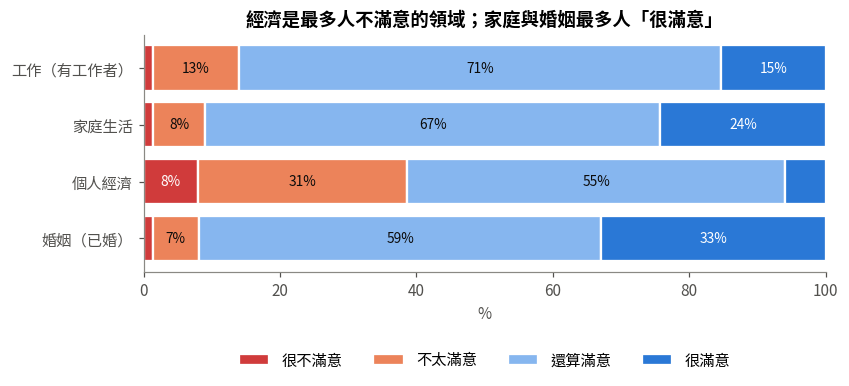

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.8))
cols = ["#d03b3b", "#ec835a", "#86b6ef", "#2a78d6"]
left = np.zeros(4)
for i, k in enumerate(lab.values()):
    v = dist.loc[k].values * 100
    ax.barh(dist.columns, v, left=left, color=cols[i], label=k, edgecolor="white", linewidth=1.5)
    for j, (l, w) in enumerate(zip(left, v)):
        if w > 6: ax.text(l + w / 2, j, f"{w:.0f}%", ha="center", va="center", fontsize=9, color="white" if i in (0, 3) else "#0b0b0b")
    left += v
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("%"); ax.grid(False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.28))
ax.set_title("經濟是最多人不滿意的領域；家庭與婚姻最多人「很滿意」")
savefig(fig, "fig02_domain_satisfaction")

## 3. 年齡與幸福：U 型嗎？

,mean,count,std,se
age5,,,,
25.0,65.24,722,16.40,0.61
30.0,64.82,2957,16.89,0.31
35.0,65.08,3748,17.15,0.28
40.0,65.19,3980,17.09,0.27
45.0,66.15,1329,16.51,0.45
50.0,66.97,483,17.13,0.78
55.0,66.71,462,18.23,0.85
60.0,67.69,519,18.43,0.81
65.0,69.06,764,18.24,0.66


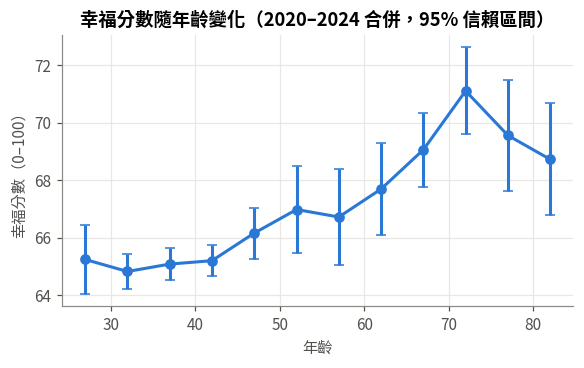

In [5]:
d = main.dropna(subset=["swb", "age"])
d["age5"] = (d.age // 5 * 5).clip(25, 80)
t = d.groupby("age5").swb.agg(["mean", "count", "std"])
t["se"] = t["std"] / np.sqrt(t["count"])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(t.index + 2, t["mean"], yerr=1.96 * t.se, color=PALETTE["blue"], marker="o", capsize=3)
ax.set_xlabel("年齡"); ax.set_ylabel("幸福分數（0–100）")
ax.set_title("幸福分數隨年齡變化（2020–2024 合併，95% 信賴區間）")
savefig(fig, "fig02b_swb_by_age")
t.round(2)

In [6]:
m = smf.ols("swb ~ age + I(age**2) + female + web + C(year)", d).fit(cov_type="cluster", cov_kwds={"groups": d.pid})
print(m.summary().tables[1])
if m.params["I(age ** 2)"] > 0:
    print("U 型最低點年齡 ≈", round(-m.params["age"] / (2 * m.params["I(age ** 2)"]), 1))

                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          63.2885      2.593     24.403      0.000      58.205      68.372
C(year)[T.2022]    -0.6059      0.243     -2.494      0.013      -1.082      -0.130
C(year)[T.2024]     1.2509      0.268      4.666      0.000       0.725       1.776
age                -0.0008      0.107     -0.008      0.994      -0.211       0.209
I(age ** 2)         0.0011      0.001      1.037      0.300      -0.001       0.003
female              0.1546      0.390      0.397      0.691      -0.609       0.918
web                 0.5314      0.415      1.282      0.200      -0.281       1.344
U 型最低點年齡 ≈ 0.4


## 4. 18 年趨勢：兩題版幸福分數與三個領域滿意度（2007–2024）

In [7]:
tr = long.groupby("year")[["swb2", "jobsat", "famsat", "health"]].mean()
tr["N"] = long.groupby("year").size()
tr.round(2)

,swb2,jobsat,famsat,health,N
year,,,,,
2007,62.05,2.95,3.14,3.35,3112
2008,62.18,2.96,3.14,3.34,3348
2009,59.58,2.94,3.12,3.39,3208
2010,62.91,2.92,3.16,3.46,5073
2011,65.32,2.94,3.16,3.42,4885
2012,65.76,2.99,3.21,3.44,4990
2014,64.97,3.00,3.20,3.41,4672
2016,66.64,3.02,3.20,3.43,4774
2018,67.44,3.00,3.20,3.43,6287


PosixPath('figures/fig02c_swb_trend.png')

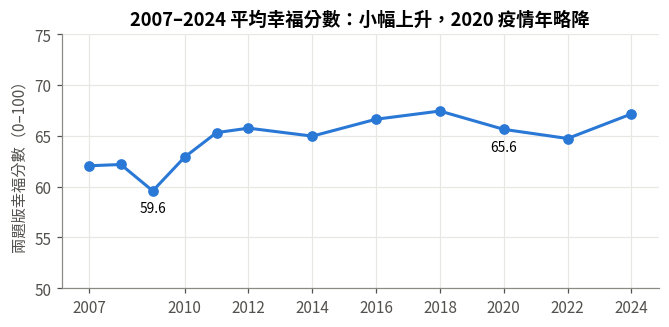

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(tr.index, tr.swb2, marker="o", color=PALETTE["blue"])
ax.set_ylim(50, 75); ax.set_ylabel("兩題版幸福分數（0–100）")
ax.set_xticks([2007, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])
ax.set_title("2007–2024 平均幸福分數：小幅上升，2020 疫情年略降")
for yy in [2009, 2020]:
    ax.annotate(f"{tr.loc[yy, 'swb2']:.1f}", (yy, tr.loc[yy, "swb2"]), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=9)
savefig(fig, "fig02c_swb_trend")

## 5. 「家庭比工作滿意」的人有多少？

In [9]:
e = main[main.employed == 1].dropna(subset=["jobsat", "famsat"])
print("家庭滿意度 > 工作滿意度：", round((e.famsat > e.jobsat).mean() * 100, 1), "%")
print("家庭滿意度 = 工作滿意度：", round((e.famsat == e.jobsat).mean() * 100, 1), "%")
print("家庭滿意度 < 工作滿意度：", round((e.famsat < e.jobsat).mean() * 100, 1), "%")
print("\n工作 × 家庭滿意度交叉表（%）")
(pd.crosstab(e.jobsat.map(lab), e.famsat.map(lab), normalize=True) * 100).round(1).reindex(index=list(lab.values()), columns=list(lab.values()))

家庭滿意度 > 工作滿意度： 24.7 %
家庭滿意度 = 工作滿意度： 63.5 %
家庭滿意度 < 工作滿意度： 11.9 %

工作 × 家庭滿意度交叉表（%）


famsat,很不滿意,不太滿意,還算滿意,很滿意
jobsat,,,,
很不滿意,0.2,0.4,0.7,0.1
不太滿意,0.3,2.5,8.3,1.3
還算滿意,0.6,4.2,52.1,13.9
很滿意,0.1,0.4,6.3,8.6


In [10]:
print("工作滿意度與家庭滿意度的相關 r =", round(e.jobsat.corr(e.famsat), 3))
print("工作與經濟滿意度 r =", round(e.jobsat.corr(e.econsat), 3), "；家庭與經濟 r =", round(e.famsat.corr(e.econsat), 3))

工作滿意度與家庭滿意度的相關 r = 0.341
工作與經濟滿意度 r = 0.406 ；家庭與經濟 r = 0.355
